In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
file_path = "../data/processed/indian_basket_crude_processed.csv"

df = pd.read_csv(file_path)

df.head()

,date,crude_oil_price,previous_crude_price,crude_price_change,crude_return,log_return,crude_ma_3,crude_ma_6,crude_ma_12,volatility_3m,volatility_6m,volatility_12m,momentum_3m,momentum_6m,price_vs_ma_3,price_vs_ma_6,price_vs_ma_12,target_next_month_crude_price,target_next_month_change
0,2001-04-01,24.82,23.82,1.00,0.041982,0.041124,24.853333,25.459437,27.106289,0.083810,0.120968,0.108141,0.033306,-0.186230,-0.001341,-0.025116,-0.084345,26.95,2.13
1,2001-05-01,26.95,24.82,2.13,0.085818,0.082334,25.196667,24.796667,27.135456,0.086492,0.129098,0.097652,0.039738,-0.128582,0.069586,0.086840,-0.006834,26.63,-0.32
2,2001-06-01,26.63,26.95,-0.32,-0.011874,-0.011945,26.133333,25.360000,26.980456,0.048931,0.062575,0.095538,0.117968,0.145376,0.019005,0.050079,-0.012989,23.99,-2.64
3,2001-07-01,23.99,26.63,-2.64,-0.099136,-0.104401,25.856667,25.355000,26.707956,0.092526,0.079850,0.099085,-0.033441,-0.001249,-0.072193,-0.053836,-0.101766,25.01,1.02
4,2001-08-01,25.01,23.99,1.02,0.042518,0.041639,25.210000,25.203333,26.431385,0.071460,0.074013,0.099226,-0.071985,-0.035108,-0.007933,-0.007671,-0.053776,24.79,-0.22


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Info:")
df.info()

Shape: (299, 19)

Columns:
['date', 'crude_oil_price', 'previous_crude_price', 'crude_price_change', 'crude_return', 'log_return', 'crude_ma_3', 'crude_ma_6', 'crude_ma_12', 'volatility_3m', 'volatility_6m', 'volatility_12m', 'momentum_3m', 'momentum_6m', 'price_vs_ma_3', 'price_vs_ma_6', 'price_vs_ma_12', 'target_next_month_crude_price', 'target_next_month_change']

Data Types:
date                              object
crude_oil_price                  float64
previous_crude_price             float64
crude_price_change               float64
crude_return                     float64
log_return                       float64
crude_ma_3                       float64
crude_ma_6                       float64
crude_ma_12                      float64
volatility_3m                    float64
volatility_6m                    float64
volatility_12m                   float64
momentum_3m                      float64
momentum_6m                      float64
price_vs_ma_3                    float64
pri

In [4]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2001-04-01 00:00:00
End Date: 2026-02-01 00:00:00


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
date                             0
crude_oil_price                  0
previous_crude_price             0
crude_price_change               0
crude_return                     0
log_return                       0
crude_ma_3                       0
crude_ma_6                       0
crude_ma_12                      0
volatility_3m                    0
volatility_6m                    0
volatility_12m                   0
momentum_3m                      0
momentum_6m                      0
price_vs_ma_3                    0
price_vs_ma_6                    0
price_vs_ma_12                   0
target_next_month_crude_price    0
target_next_month_change         0
dtype: int64

Total Missing Values: 0


In [6]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

Duplicate Rows: 0
Duplicate Dates: 0


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,299,2013-08-31 10:26:05.217391360,2001-04-01 00:00:00,2007-06-16 00:00:00,2013-09-01 00:00:00,2019-11-16 00:00:00,2026-02-01 00:00:00,NaN
crude_oil_price,299.0,67.450504,18.24,46.819186,66.897535,84.201932,132.471248,26.964138
previous_crude_price,299.0,67.299382,18.24,46.630939,66.74,84.201932,132.471248,27.081759
crude_price_change,299.0,0.151122,-27.691365,-2.561671,0.966011,3.722355,18.807077,5.736758
crude_return,299.0,0.008106,-0.403404,-0.039739,0.016913,0.065028,0.537837,0.093871
log_return,299.0,0.003557,-0.516515,-0.040551,0.016771,0.063002,0.430377,0.096716
crude_ma_3,299.0,67.308325,18.466667,46.912631,67.058719,84.528559,127.698522,26.757323
crude_ma_6,299.0,67.113049,19.714998,47.619502,66.381769,83.791679,116.93832,26.381509
crude_ma_12,299.0,66.722075,22.179673,48.084971,66.503863,84.094913,111.862381,25.678804
volatility_3m,299.0,0.066703,0.004991,0.03831,0.057332,0.085769,0.539412,0.054246


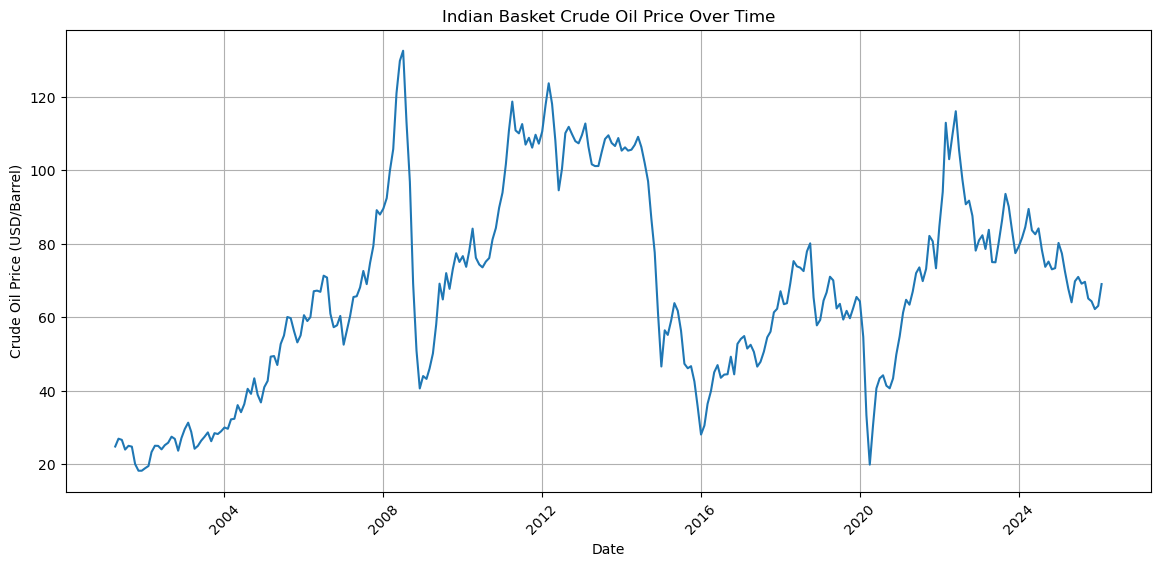

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["crude_oil_price"]
)

plt.title("Indian Basket Crude Oil Price Over Time")
plt.xlabel("Date")
plt.ylabel("Crude Oil Price (USD/Barrel)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

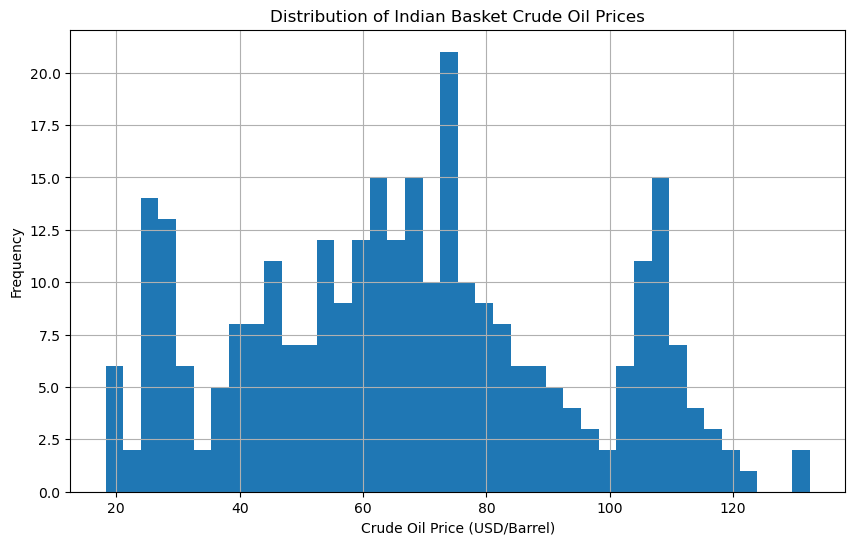

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["crude_oil_price"].dropna(),
    bins=40
)

plt.title("Distribution of Indian Basket Crude Oil Prices")
plt.xlabel("Crude Oil Price (USD/Barrel)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

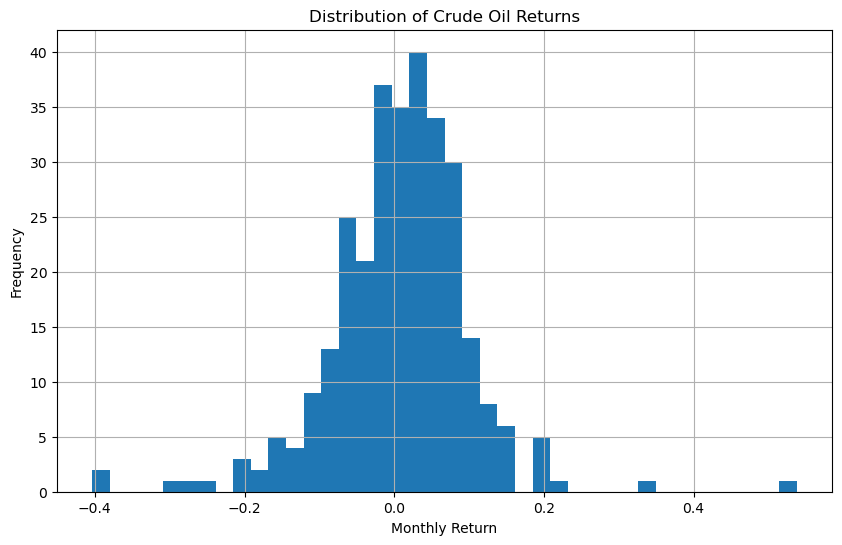

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["crude_return"].dropna(),
    bins=40
)

plt.title("Distribution of Crude Oil Returns")
plt.xlabel("Monthly Return")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

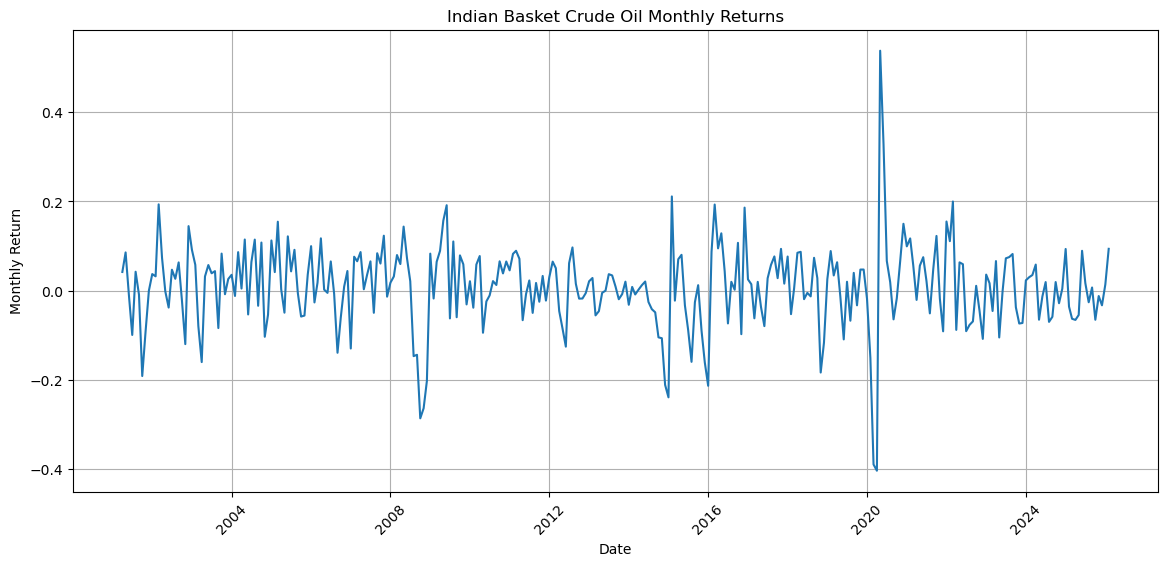

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["crude_return"]
)

plt.title("Indian Basket Crude Oil Monthly Returns")
plt.xlabel("Date")
plt.ylabel("Monthly Return")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [12]:
print("Mean Return:", df["crude_return"].mean())
print("Median Return:", df["crude_return"].median())
print("Standard Deviation:", df["crude_return"].std())
print("Minimum Return:", df["crude_return"].min())
print("Maximum Return:", df["crude_return"].max())

Mean Return: 0.008105596763551586
Median Return: 0.016912713200516
Standard Deviation: 0.0938710344689577
Minimum Return: -0.4034041782598908
Maximum Return: 0.537836697744082


In [13]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility Columns:")
print(volatility_columns)

Volatility Columns:
['volatility_3m', 'volatility_6m', 'volatility_12m']


In [14]:
if "volatility_12m" in df.columns:
    volatility_col = "volatility_12m"
elif "volatility_6m" in df.columns:
    volatility_col = "volatility_6m"
else:
    volatility_col = volatility_columns[-1]

print("Selected Volatility Column:", volatility_col)

Selected Volatility Column: volatility_12m


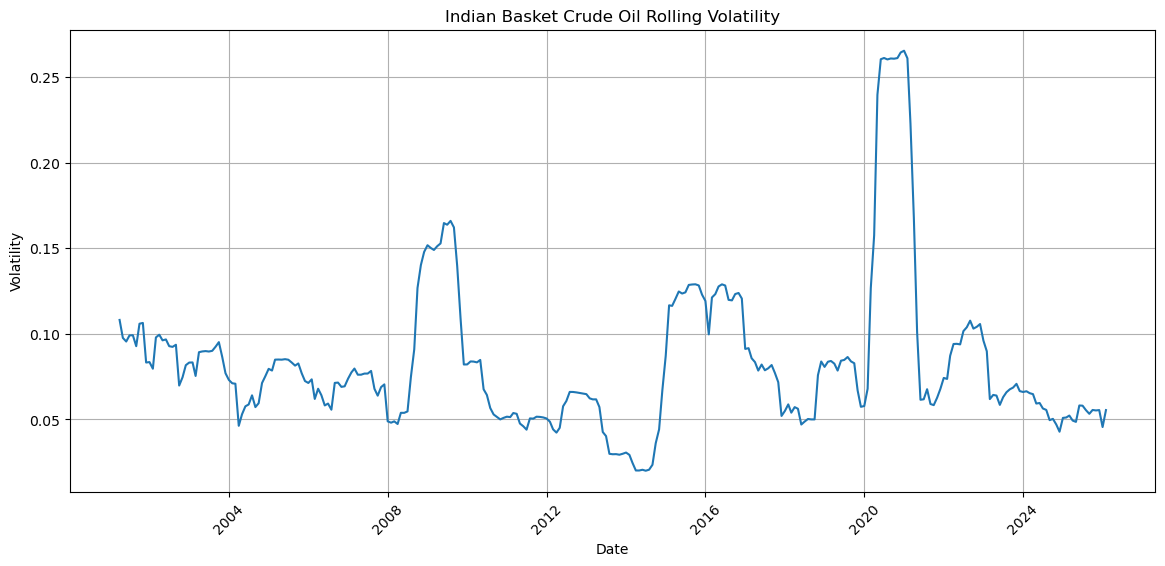

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df[volatility_col]
)

plt.title("Indian Basket Crude Oil Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [16]:
df[volatility_col].describe()

count    299.000000
mean       0.083361
std        0.044746
min        0.020073
25%        0.056346
50%        0.073443
75%        0.093232
max        0.265376
Name: volatility_12m, dtype: float64

In [17]:
highest_volatility = (
    df[["date", volatility_col]]
    .sort_values(
        by=volatility_col,
        ascending=False
    )
    .head(10)
)

highest_volatility

,date,volatility_12m
237,2021-01-01,0.265376
236,2020-12-01,0.264356
231,2020-07-01,0.261134
235,2020-11-01,0.261074
238,2021-02-01,0.260930
233,2020-09-01,0.260850
234,2020-10-01,0.260714
230,2020-06-01,0.260403
232,2020-08-01,0.260288
229,2020-05-01,0.239614


In [18]:
ma_columns = [
    col for col in df.columns
    if col.startswith("crude_ma_")
]

print("Moving Average Columns:")
print(ma_columns)

Moving Average Columns:
['crude_ma_3', 'crude_ma_6', 'crude_ma_12']


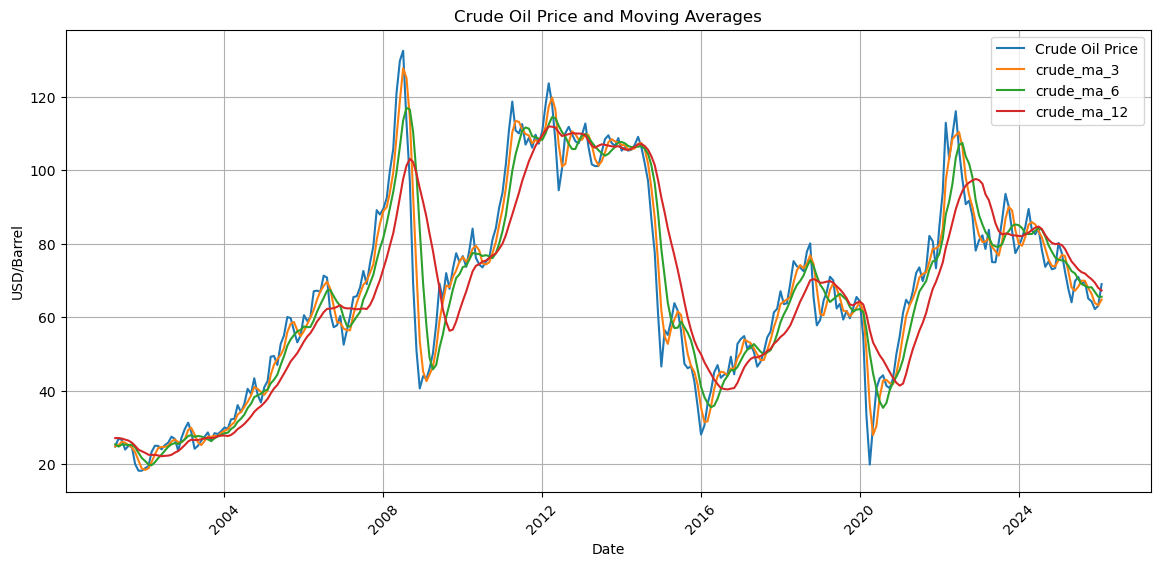

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["crude_oil_price"],
    label="Crude Oil Price"
)

for col in ma_columns:
    plt.plot(
        df["date"],
        df[col],
        label=col
    )

plt.title("Crude Oil Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("USD/Barrel")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [20]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum Columns:")
print(momentum_columns)

Momentum Columns:
['momentum_3m', 'momentum_6m']


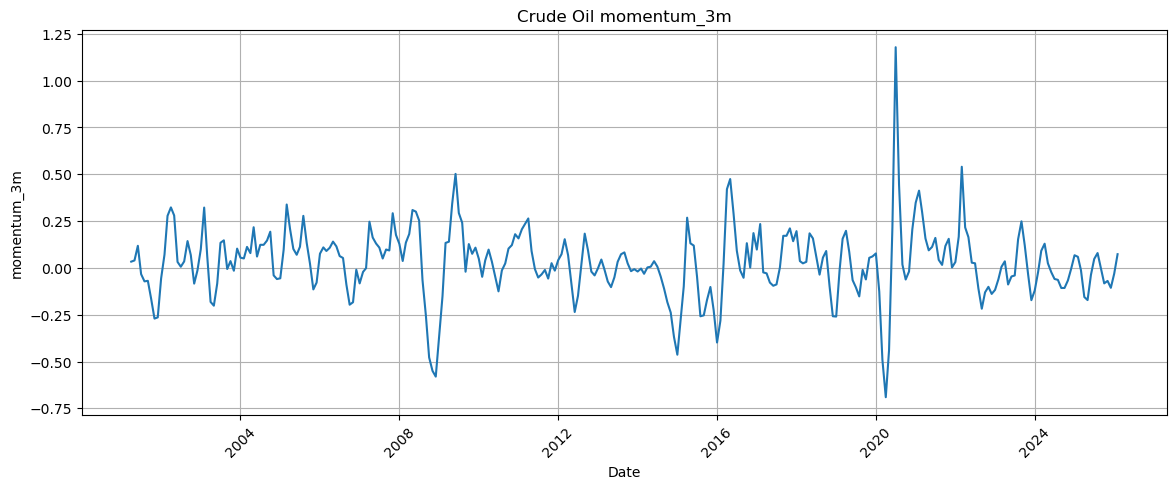

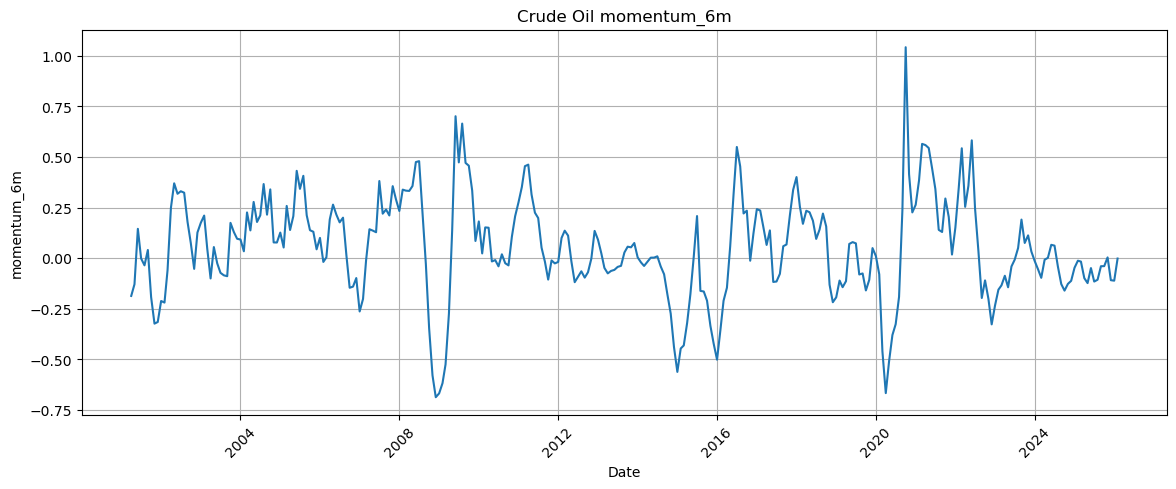

In [21]:
for col in momentum_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["date"],
        df[col]
    )

    plt.title(f"Crude Oil {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [22]:
price_ma_columns = [
    col for col in df.columns
    if "price_vs_ma" in col.lower()
]

print(price_ma_columns)

['price_vs_ma_3', 'price_vs_ma_6', 'price_vs_ma_12']


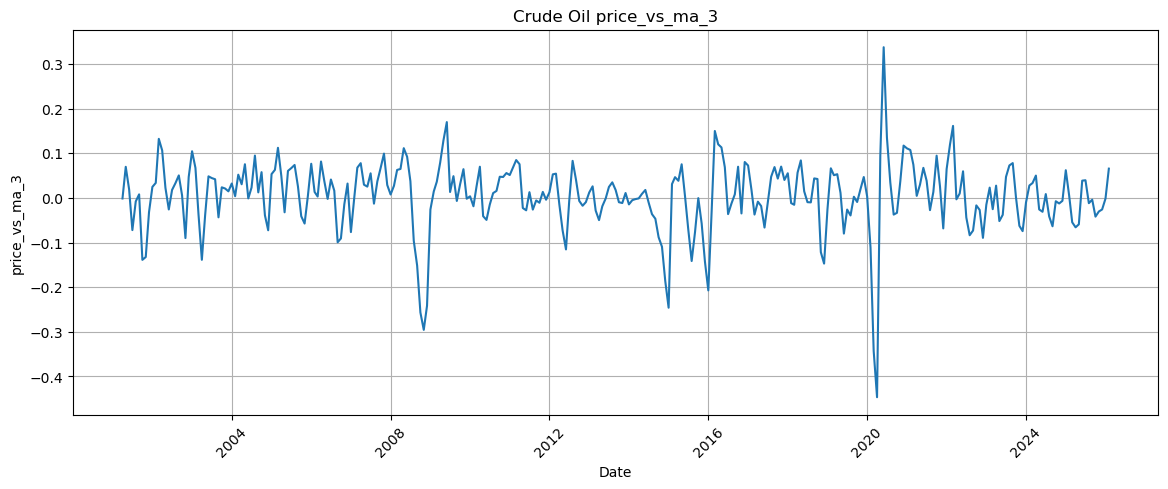

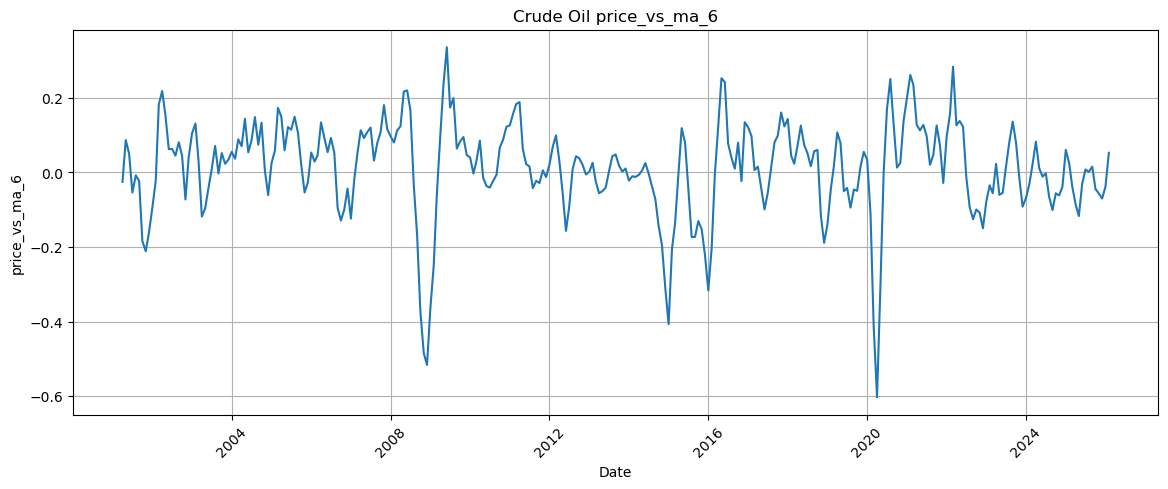

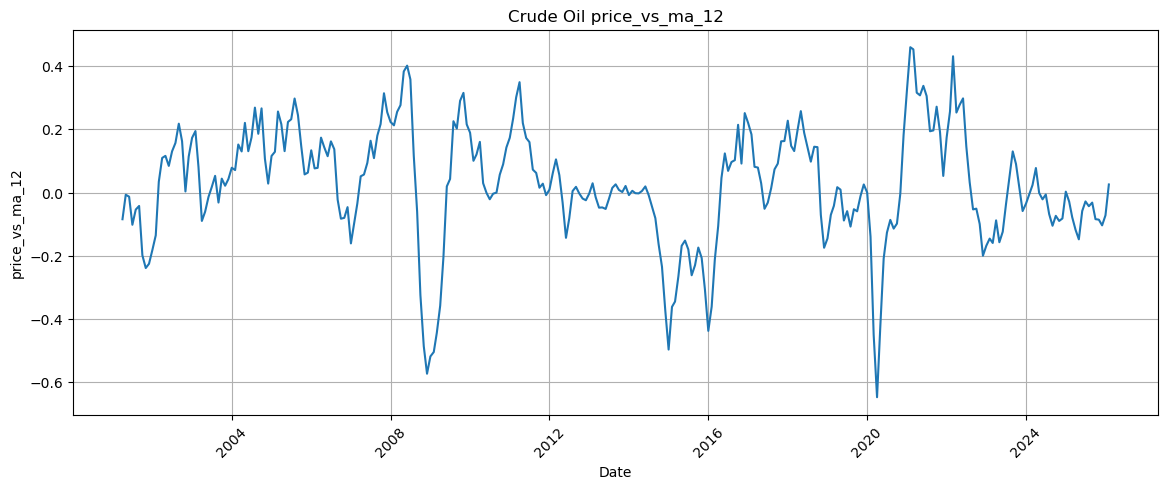

In [23]:
for col in price_ma_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        df["date"],
        df[col]
    )

    plt.title(f"Crude Oil {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [24]:
target_col = "target_next_month_crude_price"

print("Target Column:", target_col)

print("\nTarget Statistics:")
print(df[target_col].describe())

Target Column: target_next_month_crude_price

Target Statistics:
count    299.000000
mean      67.747059
std       26.981305
min       18.240000
25%       46.979168
50%       66.953085
75%       84.371291
max      132.471248
Name: target_next_month_crude_price, dtype: float64


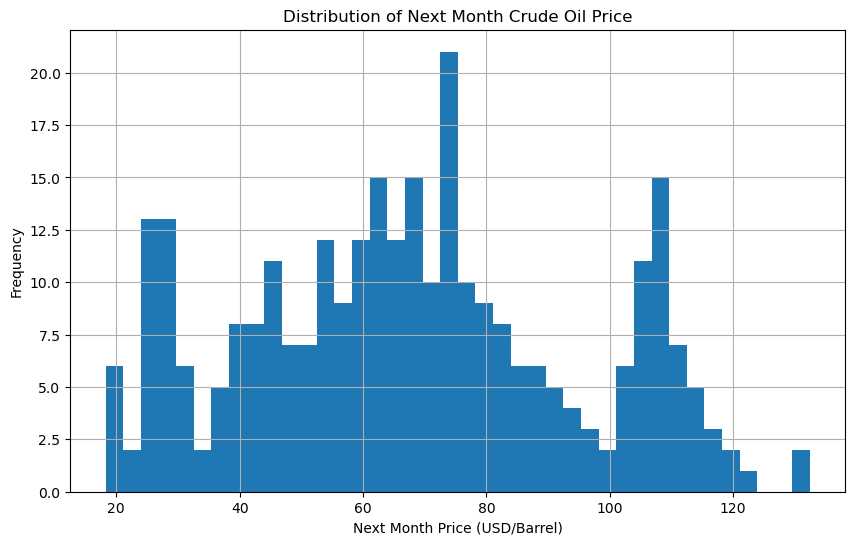

In [25]:
plt.figure(figsize=(10, 6))

plt.hist(
    df[target_col].dropna(),
    bins=40
)

plt.title("Distribution of Next Month Crude Oil Price")
plt.xlabel("Next Month Price (USD/Barrel)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

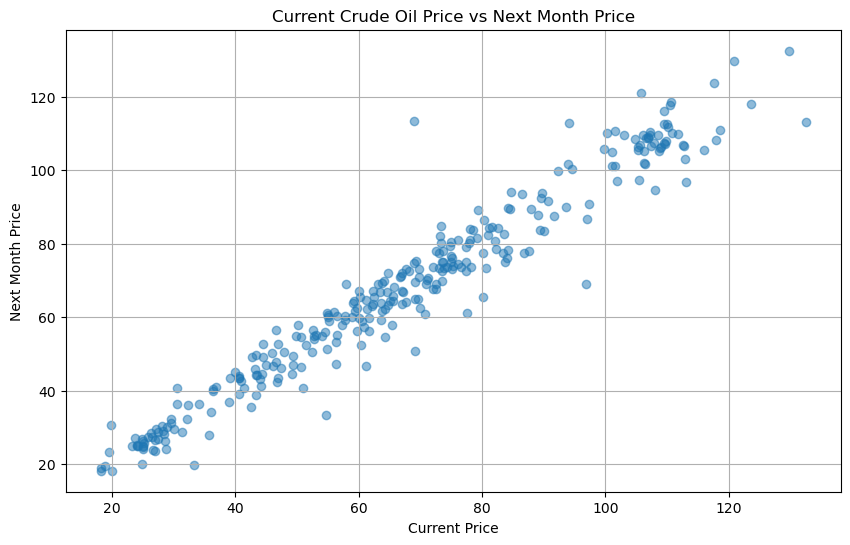

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["crude_oil_price"],
    df[target_col],
    alpha=0.5
)

plt.title("Current Crude Oil Price vs Next Month Price")
plt.xlabel("Current Price")
plt.ylabel("Next Month Price")
plt.grid(True)

plt.show()

In [27]:
corr = df.corr(numeric_only=True)

target_correlations = (
    corr[target_col]
    .sort_values(ascending=False)
)

target_correlations

target_next_month_crude_price    1.000000
crude_oil_price                  0.972866
crude_ma_3                       0.943237
previous_crude_price             0.933072
crude_ma_6                       0.903484
crude_ma_12                      0.843056
price_vs_ma_12                   0.288290
momentum_6m                      0.205575
price_vs_ma_6                    0.205505
crude_price_change               0.167910
price_vs_ma_3                    0.150072
momentum_3m                      0.139437
log_return                       0.125654
target_next_month_change         0.119173
crude_return                     0.100232
volatility_3m                   -0.306281
volatility_6m                   -0.389696
volatility_12m                  -0.428686
Name: target_next_month_crude_price, dtype: float64

In [28]:
strongest_features = (
    target_correlations
    .drop(target_col)
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("Strongest Feature Correlations:")
print(strongest_features.head(15))

Strongest Feature Correlations:
crude_oil_price         0.972866
crude_ma_3              0.943237
previous_crude_price    0.933072
crude_ma_6              0.903484
crude_ma_12             0.843056
volatility_12m         -0.428686
volatility_6m          -0.389696
volatility_3m          -0.306281
price_vs_ma_12          0.288290
momentum_6m             0.205575
price_vs_ma_6           0.205505
crude_price_change      0.167910
price_vs_ma_3           0.150072
momentum_3m             0.139437
log_return              0.125654
Name: target_next_month_crude_price, dtype: float64


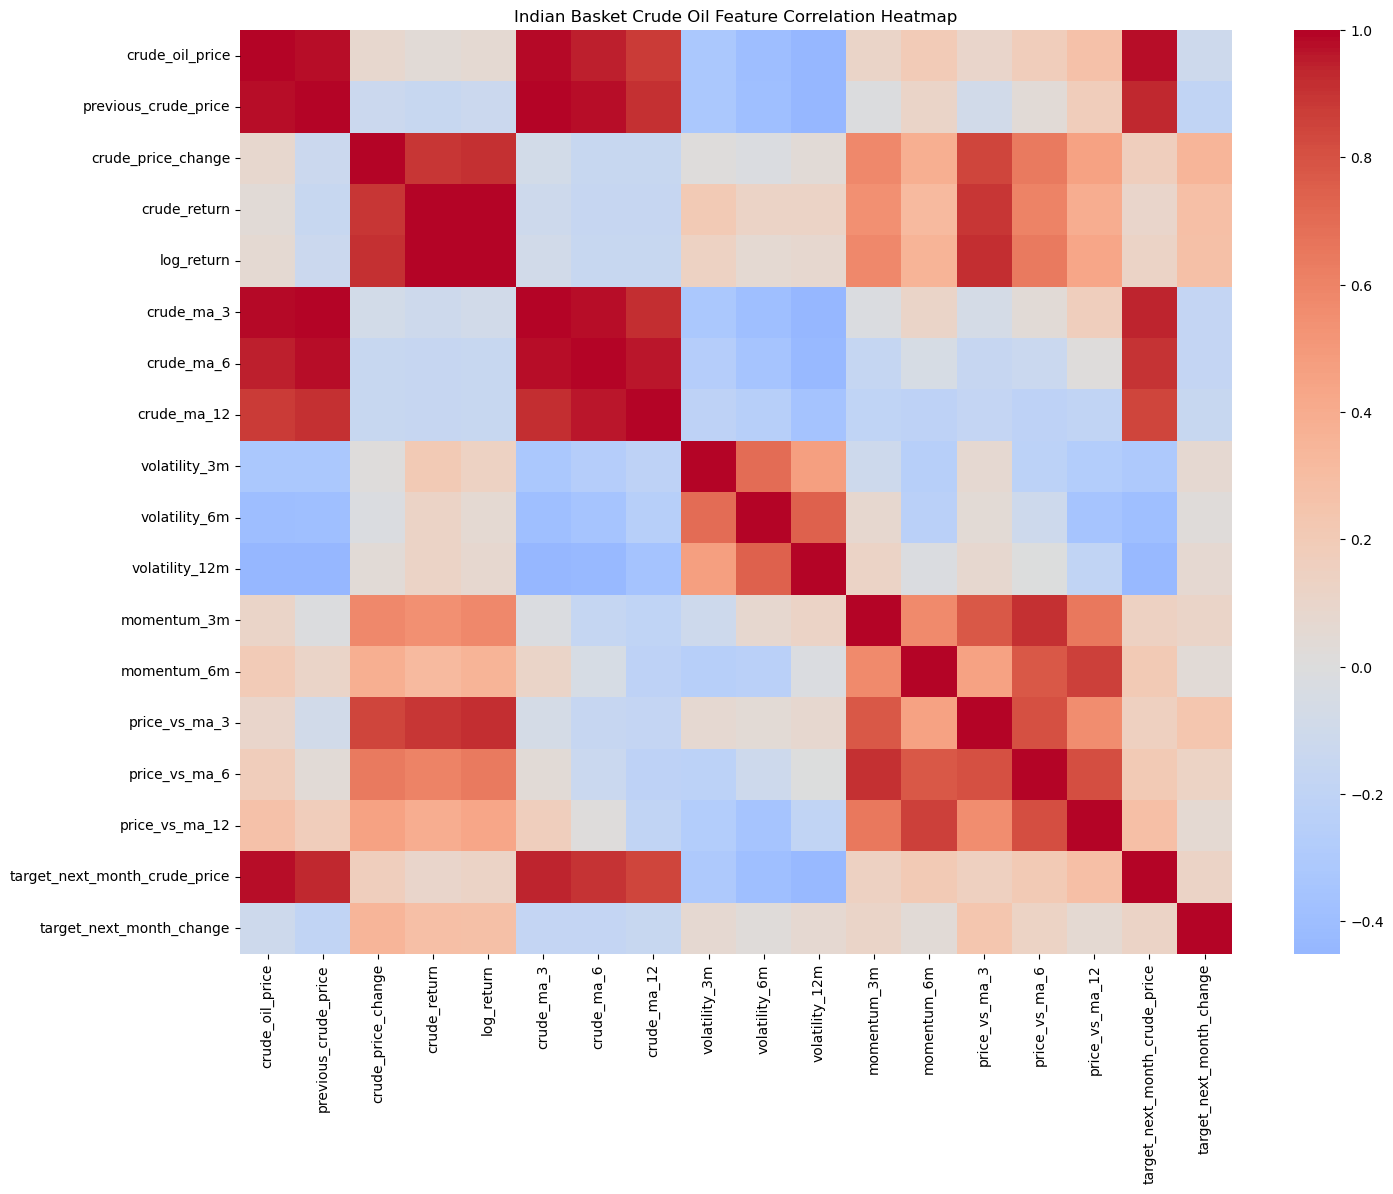

In [29]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Indian Basket Crude Oil Feature Correlation Heatmap")

plt.show()

In [30]:
extreme_changes = (
    df[
        ["date", "crude_oil_price", "crude_price_change", "crude_return"]
    ]
    .sort_values(
        by="crude_return",
        key=abs,
        ascending=False
    )
    .head(15)
)

extreme_changes

,date,crude_oil_price,crude_price_change,crude_return
229,2020-05-01,30.605540,10.703856,0.537837
228,2020-04-01,19.901684,-13.457054,-0.403404
227,2020-03-01,33.358738,-21.268622,-0.389340
230,2020-06-01,40.633869,10.028329,0.327664
90,2008-10-01,69.121527,-27.691365,-0.286030
91,2008-11-01,50.907636,-18.213891,-0.263505
165,2015-01-01,46.586617,-14.624481,-0.238919
177,2016-01-01,28.078798,-7.602090,-0.213058
166,2015-02-01,56.430382,9.843765,0.211300
164,2014-12-01,61.211098,-16.370353,-0.211009


In [31]:
print("Lowest Crude Oil Price:")
print(
    df.loc[
        df["crude_oil_price"].idxmin(),
        ["date", "crude_oil_price"]
    ]
)

print("\nHighest Crude Oil Price:")
print(
    df.loc[
        df["crude_oil_price"].idxmax(),
        ["date", "crude_oil_price"]
    ]
)

Lowest Crude Oil Price:
date               2001-11-01 00:00:00
crude_oil_price                  18.24
Name: 7, dtype: object

Highest Crude Oil Price:
date               2008-07-01 00:00:00
crude_oil_price             132.471248
Name: 87, dtype: object


In [32]:
print("FINAL DATA QUALITY CHECK")
print("------------------------")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

print("Date Start:", df["date"].min())
print("Date End:", df["date"].max())

FINAL DATA QUALITY CHECK
------------------------
Rows: 299
Columns: 19
Missing Values: 0
Duplicate Rows: 0
Duplicate Dates: 0
Date Start: 2001-04-01 00:00:00
Date End: 2026-02-01 00:00:00


In [33]:
summary = {
    "rows": len(df),
    "columns": len(df.columns),
    "date_start": df["date"].min(),
    "date_end": df["date"].max(),
    "missing_values": df.isnull().sum().sum(),
    "duplicate_rows": df.duplicated().sum(),
    "mean_crude_price": df["crude_oil_price"].mean(),
    "min_crude_price": df["crude_oil_price"].min(),
    "max_crude_price": df["crude_oil_price"].max(),
    "mean_crude_return": df["crude_return"].mean(),
    "return_std": df["crude_return"].std(),
    "mean_volatility": df[volatility_col].mean(),
    "max_volatility": df[volatility_col].max()
}

summary_df = pd.DataFrame([summary])

summary_df

,rows,columns,date_start,date_end,missing_values,duplicate_rows,mean_crude_price,min_crude_price,max_crude_price,mean_crude_return,return_std,mean_volatility,max_volatility
0,299,19,2001-04-01,2026-02-01,0,0,67.450504,18.24,132.471248,0.008106,0.093871,0.083361,0.265376


In [34]:
output_path = "../data/processed/indian_basket_crude_eda_summary.csv"

summary_df.to_csv(
    output_path,
    index=False
)

print("EDA summary saved successfully!")
print(output_path)

EDA summary saved successfully!
../data/processed/indian_basket_crude_eda_summary.csv
